# **CHƯƠNG 4. THỰC NGHIỆM VÀ PHÂN TÍCH SỰ BÃO HÒA HIỆU NĂNG CỦA SpMV**

**Đề tài:** Phép nhân ma trận thưa với vector song song: Phân tích sự bão hòa hiệu năng và ứng dụng trong phương pháp lặp Jacobi  
**Phân công thực hiện:**  
- **Viết báo cáo:** Thành  
- **Cài đặt thuật toán, đo đạc và xuất biểu đồ:** Thanh  

---
Chương này thực hiện toàn bộ các đo đạc thực nghiệm trên 5 bộ ma trận thưa kích thước lớn ($N \in \{20000, 60000, 100000, 200000, 600000\}$), quét qua các mức số luồng $p \in \{1, 2, 4, 5, 6, 7, 8\}$. Các chỉ số thời gian thực thi, Speedup, Efficiency và Băng thông hiệu dụng được tính toán, phân tích và trực quan hóa bằng các biểu đồ tương ứng ngay trong notebook, từ đó xác định chính xác điểm bão hòa và làm rõ các nguyên nhân vật lý dẫn đến hiện tượng bão hòa hiệu năng.


## **4.1. Mục tiêu thực nghiệm**

Thực nghiệm được thiết kế nhằm trả lời 3 câu hỏi nghiên cứu cốt lõi:
1. **Quy luật tăng tốc:** Khi tăng số luồng song song từ $p = 1$ lên $p = 8$ trên các ma trận lớn từ $20k$ đến $600k$, thời gian thực thi giảm và Speedup tăng theo quy luật như thế nào?
2. **Xác định điểm bão hòa:** Tại ngưỡng số luồng nào thì hiệu năng bắt đầu bão hòa?
3. **Giải thích nguyên nhân:** Tại sao SpMV lại bị bão hòa sớm trên kiến trúc đa nhân? Phân tích thắt cổ chai băng thông bộ nhớ (Memory-Bound) và hạn chế của Hyper-Threading.


## **4.2. Thiết kế thực nghiệm và Thu thập số liệu**

### Kịch bản thực nghiệm:
- **Biến độc lập:**
  - 5 kích thước ma trận: $N \in \{20000, 60000, 100000, 200000, 600000\}$ ($NNZ \approx 4.2 \times 10^5 \dots 1.26 \times 10^7$).
  - 4 mức số luồng thực thi: $p \in \{1, 2, 4, 5, 6, 7, 8\}$.
- **Quy trình đo:**
  - Mỗi kịch bản chạy warm-up 5 lần để ổn định JIT và Cache.
  - Đo chính thức 20 lần lặp độc lập bằng `time.perf_counter()`.
  - Lấy giá trị **Trung vị (Median)** làm $T(p)$ đại diện.
  - Tính Speedup: $S(p) = \frac{T(1)}{T(p)}$.
  - Tính Efficiency: $E(p) = \frac{S(p)}{p} \times 100\%$.
  - Tính GFLOPS: $\text{GFLOPS} = \frac{2 \times nnz}{T(p) \times 10^9}$.
  - Tính Băng thông hiệu dụng (Effective Bandwidth GB/s):
    $$\text{BW}_{\text{eff}} = \frac{8 \cdot nnz + 4 \cdot nnz + 4 \cdot (n+1) + 8 \cdot n + 8 \cdot n}{T(p) \times 10^9}$$
- Toàn bộ dữ liệu thô được tự động ghi nhận và xuất ra file `data/spmv_benchmark_results.csv`.


In [195]:
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from numba import njit, prange, set_num_threads
import os

# Thiết lập phong cách trực quan hóa học thuật chuẩn
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#29313B'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E2E6EB'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

COLORS = ['#344767', '#7187A5', '#8FA99B', '#D9CBB8', '#E2847A']

# 1. Tái tạo 5 ma trận thực nghiệm chuẩn
def generate_diagonally_dominant_csr(n, avg_nnz_row=20, seed=42):
    rng = np.random.default_rng(seed + n)
    k = avg_nnz_row
    rows = np.repeat(np.arange(n, dtype=np.int32), k)
    cols = rng.integers(0, n, size=n * k, dtype=np.int32)
    vals = rng.uniform(0.1, 1.0, size=n * k)
    mat = sp.coo_matrix((vals, (rows, cols)), shape=(n, n), dtype=np.float64).tocsr()
    diag_vals = np.abs(mat).sum(axis=1).A1 + 5.0
    mat.setdiag(diag_vals)
    mat = mat.tocsr()
    mat.sum_duplicates()
    mat.sort_indices()
    return mat

@njit(parallel=True, fastmath=True)
def spmv_csr_parallel(values, col_indices, row_ptr, x, y, n):
    for i in prange(n):
        s = 0.0
        row_start = row_ptr[i]
        row_end = row_ptr[i + 1]
        for j in range(row_start, row_end):
            s += values[j] * x[col_indices[j]]
        y[i] = s

matrix_sizes = [20000, 60000, 100000, 200000, 600000]
thread_counts = [1, 2,3, 4,5, 6,7, 8]
matrices = {n: generate_diagonally_dominant_csr(n, 20, 42) for n in matrix_sizes}

# Chạy thực nghiệm tự động hóa
benchmark_data = []

print("Bắt đầu thực nghiệm quét tham số SpMV trên 5 ma trận mới...")
for n in matrix_sizes:
    mat = matrices[n]
    nnz = mat.nnz
    values = mat.data
    col_indices = mat.indices
    row_ptr = mat.indptr
    
    np.random.seed(42 + n)
    x = np.random.uniform(-1.0, 1.0, size=n).astype(np.float64)
    y = np.zeros(n, dtype=np.float64)
    
    bytes_transferred = (nnz * 8) + (nnz * 4) + ((n + 1) * 4) + (n * 8) + (n * 8)
    
    t1_median = None
    for p in thread_counts:
        set_num_threads(p)
        # Warmup
        for _ in range(5):
            spmv_csr_parallel(values, col_indices, row_ptr, x, y, n)
            
        # Đo 20 lần
        times = []
        for _ in range(20):
            t0 = time.perf_counter()
            spmv_csr_parallel(values, col_indices, row_ptr, x, y, n)
            t1 = time.perf_counter()
            times.append(t1 - t0)
            
        med_time = np.median(times)
        mean_time = np.mean(times)
        std_time = np.std(times)
        
        if p == 1:
            t1_median = med_time
            speedup = 1.0
            efficiency = 100.0
        else:
            speedup = t1_median / med_time
            efficiency = (speedup / p) * 100.0
            
        gflops = (2.0 * nnz) / (med_time * 1e9)
        bw_effective_gb_s = bytes_transferred / (med_time * 1e9)
        
        benchmark_data.append({
            "Matrix": f"M_{n//1000}k",
            "N": n,
            "NNZ": nnz,
            "Threads": p,
            "Time_Median_ms": med_time * 1000.0,
            "Time_Mean_ms": mean_time * 1000.0,
            "Time_Std_ms": std_time * 1000.0,
            "Speedup": speedup,
            "Efficiency_%": efficiency,
            "GFLOPS": gflops,
            "Bandwidth_GB_s": bw_effective_gb_s
        })
        print(f"Matrix M_{n//1000}k | Threads={p} | Time={med_time*1000:.3f} ms | Speedup={speedup:.2f}x | Eff={efficiency:.1f}%")

df_results = pd.DataFrame(benchmark_data)
os.makedirs("data", exist_ok=True)
df_results.to_csv("data/spmv_benchmark_results.csv", index=False, encoding="utf-8-sig")
print("\n=> Đã lưu thành công kết quả đo vào data/spmv_benchmark_results.csv")


Bắt đầu thực nghiệm quét tham số SpMV trên 5 ma trận mới...
Matrix M_20k | Threads=1 | Time=0.619 ms | Speedup=1.00x | Eff=100.0%
Matrix M_20k | Threads=2 | Time=0.407 ms | Speedup=1.52x | Eff=76.1%
Matrix M_20k | Threads=3 | Time=0.488 ms | Speedup=1.27x | Eff=42.3%
Matrix M_20k | Threads=4 | Time=0.369 ms | Speedup=1.68x | Eff=41.9%
Matrix M_20k | Threads=5 | Time=0.312 ms | Speedup=1.98x | Eff=39.7%
Matrix M_20k | Threads=6 | Time=0.218 ms | Speedup=2.83x | Eff=47.2%
Matrix M_20k | Threads=7 | Time=0.261 ms | Speedup=2.37x | Eff=33.9%
Matrix M_20k | Threads=8 | Time=0.221 ms | Speedup=2.79x | Eff=34.9%
Matrix M_60k | Threads=1 | Time=2.118 ms | Speedup=1.00x | Eff=100.0%
Matrix M_60k | Threads=2 | Time=1.385 ms | Speedup=1.53x | Eff=76.4%
Matrix M_60k | Threads=3 | Time=1.306 ms | Speedup=1.62x | Eff=54.0%
Matrix M_60k | Threads=4 | Time=1.106 ms | Speedup=1.92x | Eff=47.9%
Matrix M_60k | Threads=5 | Time=1.052 ms | Speedup=2.01x | Eff=40.3%
Matrix M_60k | Threads=6 | Time=0.963 ms 

## **4.3. Phân tích thời gian thực thi (Execution Time)**

Dưới đây là bảng tổng hợp thời gian thực thi trung vị $T(p)$ (đơn vị: mili-giây) theo số luồng cho 5 ma trận và các biểu đồ trực quan hóa.


,1 Luồng (ms),2 Luồng (ms),3 Luồng (ms),4 Luồng (ms),5 Luồng (ms),6 Luồng (ms),7 Luồng (ms),8 Luồng (ms)
Matrix,,,,,,,,
M_100k,4.636,2.721,2.529,2.449,2.030,2.000,1.816,1.660
M_200k,10.154,4.990,5.348,5.217,4.661,4.268,4.083,3.782
M_20k,0.619,0.407,0.488,0.369,0.312,0.218,0.261,0.221
M_600k,66.694,35.670,26.503,32.426,26.787,23.444,20.774,20.724
M_60k,2.118,1.385,1.306,1.106,1.052,0.963,0.940,0.891


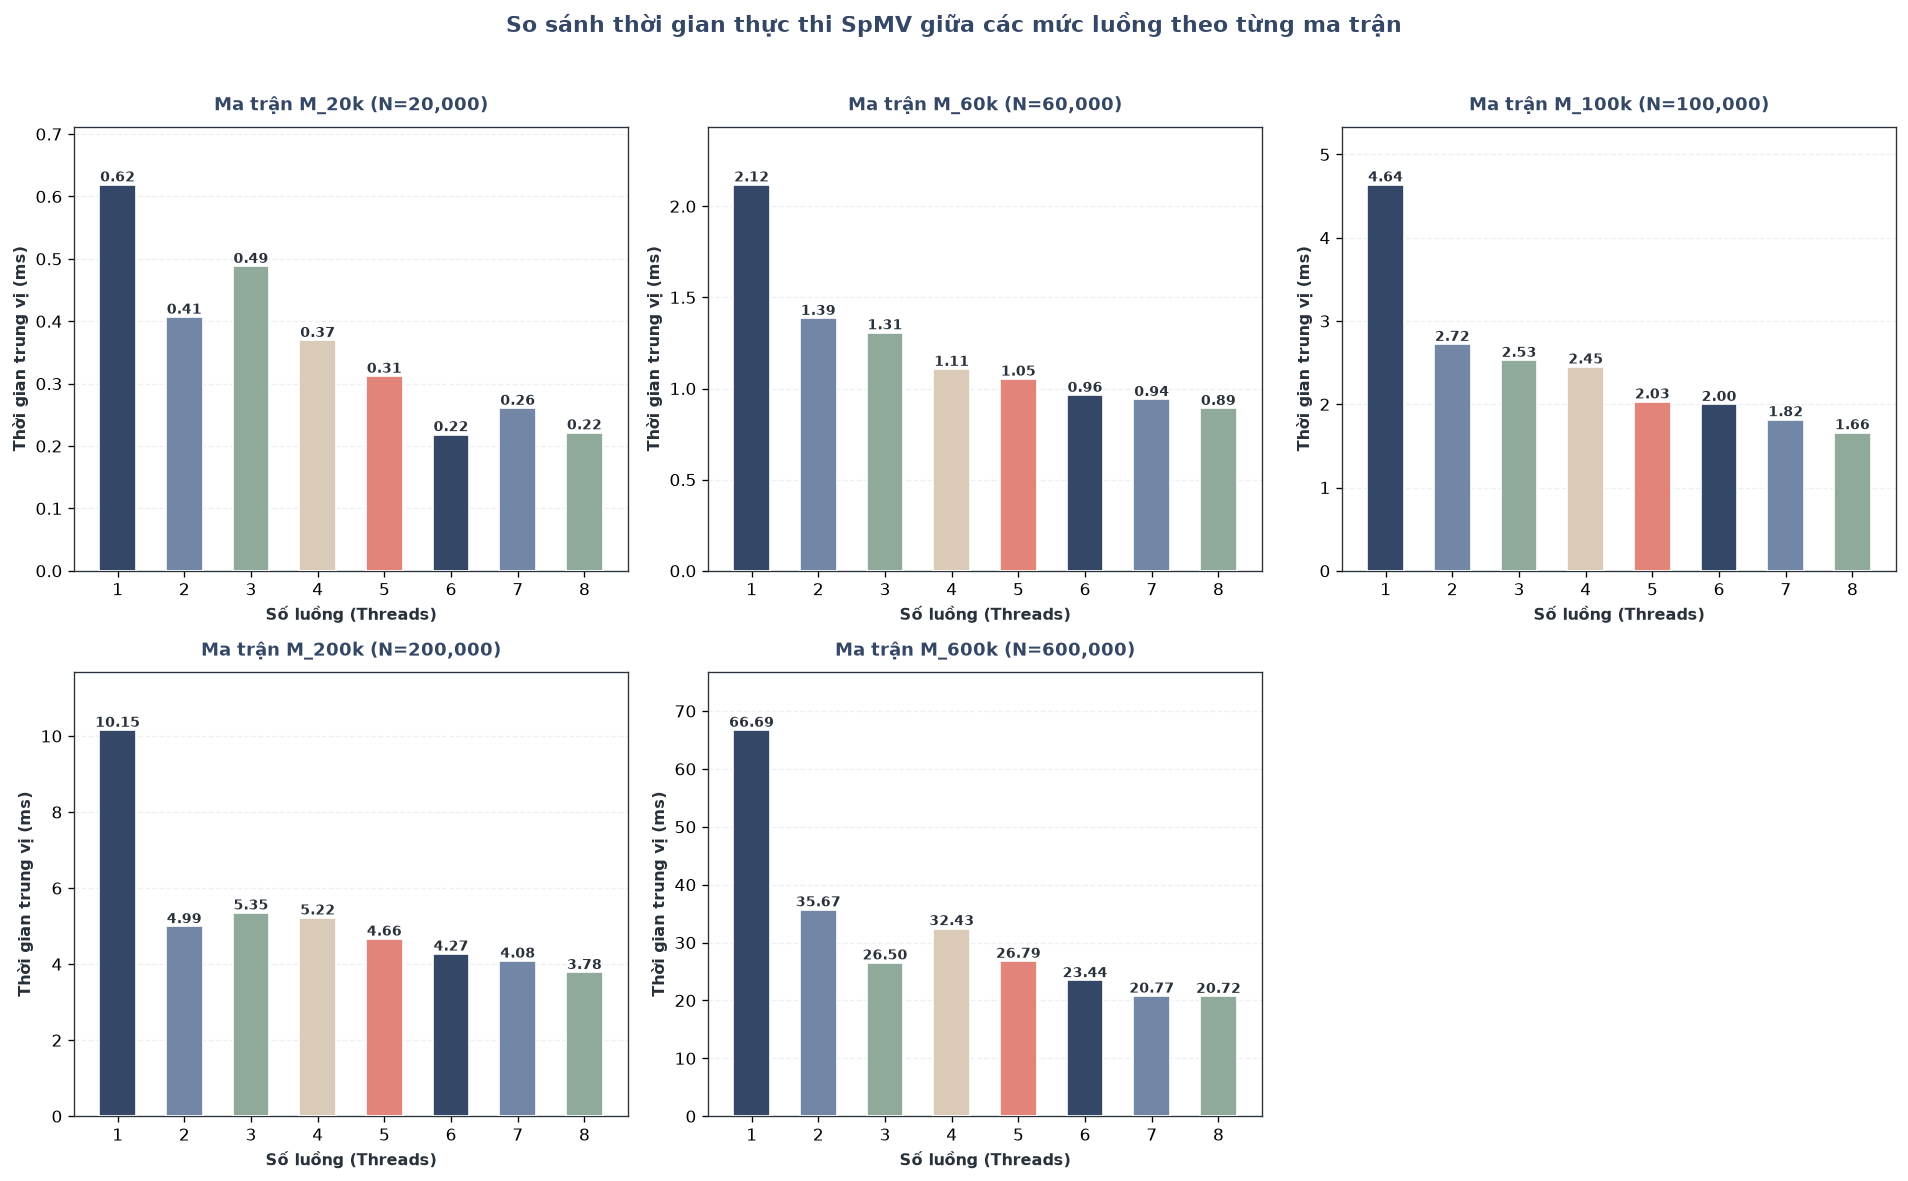

In [196]:
pivot_time = df_results.pivot(index="Matrix", columns="Threads", values="Time_Median_ms")
pivot_time.columns = [f"{c} Luồng (ms)" for c in pivot_time.columns]
display(pivot_time.round(3))

# Thiết lập lưới 2 hàng x 3 cột cho 5 ma trận
n_matrices = len(matrix_sizes)
n_cols = 3
n_rows = int(np.ceil(n_matrices / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.8 * n_rows), dpi=120)
axes = np.array(axes).flatten()

for idx, n in enumerate(matrix_sizes):
    ax = axes[idx]
    sub = df_results[df_results["N"] == n].sort_values("Threads")
    
    x_pos = np.arange(len(sub))
    bar_colors = [COLORS[i % len(COLORS)] for i in range(len(sub))]
    
    bars = ax.bar(
        x_pos,
        sub["Time_Median_ms"],
        width=0.55,
        color=bar_colors,
        edgecolor='white',
        zorder=3
    )
    
    # Gắn nhãn giá trị thời gian lên đỉnh mỗi cột
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.2f}",
            ha='center',
            va='bottom',
            fontsize=8.5,
            fontweight='bold',
            color='#29313B'
        )
    
    ax.set_title(f"Ma trận M_{n//1000}k (N={n:,})", fontsize=11, fontweight='bold', color='#344767', pad=10)
    ax.set_xlabel("Số luồng (Threads)", fontsize=9.5, fontweight='bold', color='#29313B')
    ax.set_ylabel("Thời gian trung vị (ms)", fontsize=9.5, fontweight='bold', color='#29313B')
    ax.set_xticks(x_pos)
    ax.set_xticklabels([f"{int(t)}" for t in sub["Threads"]])
    
    # Nới thêm 15% khoảng trống trục Y để số trên cột không chạm viền trên
    max_val = sub["Time_Median_ms"].max()
    if np.isfinite(max_val) and max_val > 0:
        ax.set_ylim(0, max_val * 1.15)
        
    ax.grid(True, axis='y', linestyle='--', alpha=0.6, zorder=0)

# Xóa ô đồ thị thừa (ô thứ 6)
for i in range(n_matrices, len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "So sánh thời gian thực thi SpMV giữa các mức luồng theo từng ma trận",
    fontsize=13,
    fontweight='bold',
    color='#344767',
    y=1.02
)

plt.tight_layout()
plt.show()

## **4.4. Phân tích tốc độ tăng tốc (Speedup)**

Tốc độ tăng tốc được xác định theo công thức:
$$S(p) = \frac{T(1)}{T(p)}$$
Đường lý tưởng tương ứng với tăng tốc tuyến tính hoàn hảo: $S_{\text{ideal}}(p) = p$.


,1 Luồng,2 Luồng,3 Luồng,4 Luồng,5 Luồng,6 Luồng,7 Luồng,8 Luồng
Matrix,,,,,,,,
M_100k,1.0,1.70,1.83,1.89,2.28,2.32,2.55,2.79
M_200k,1.0,2.03,1.90,1.95,2.18,2.38,2.49,2.69
M_20k,1.0,1.52,1.27,1.68,1.98,2.83,2.37,2.79
M_600k,1.0,1.87,2.52,2.06,2.49,2.84,3.21,3.22
M_60k,1.0,1.53,1.62,1.92,2.01,2.20,2.25,2.38


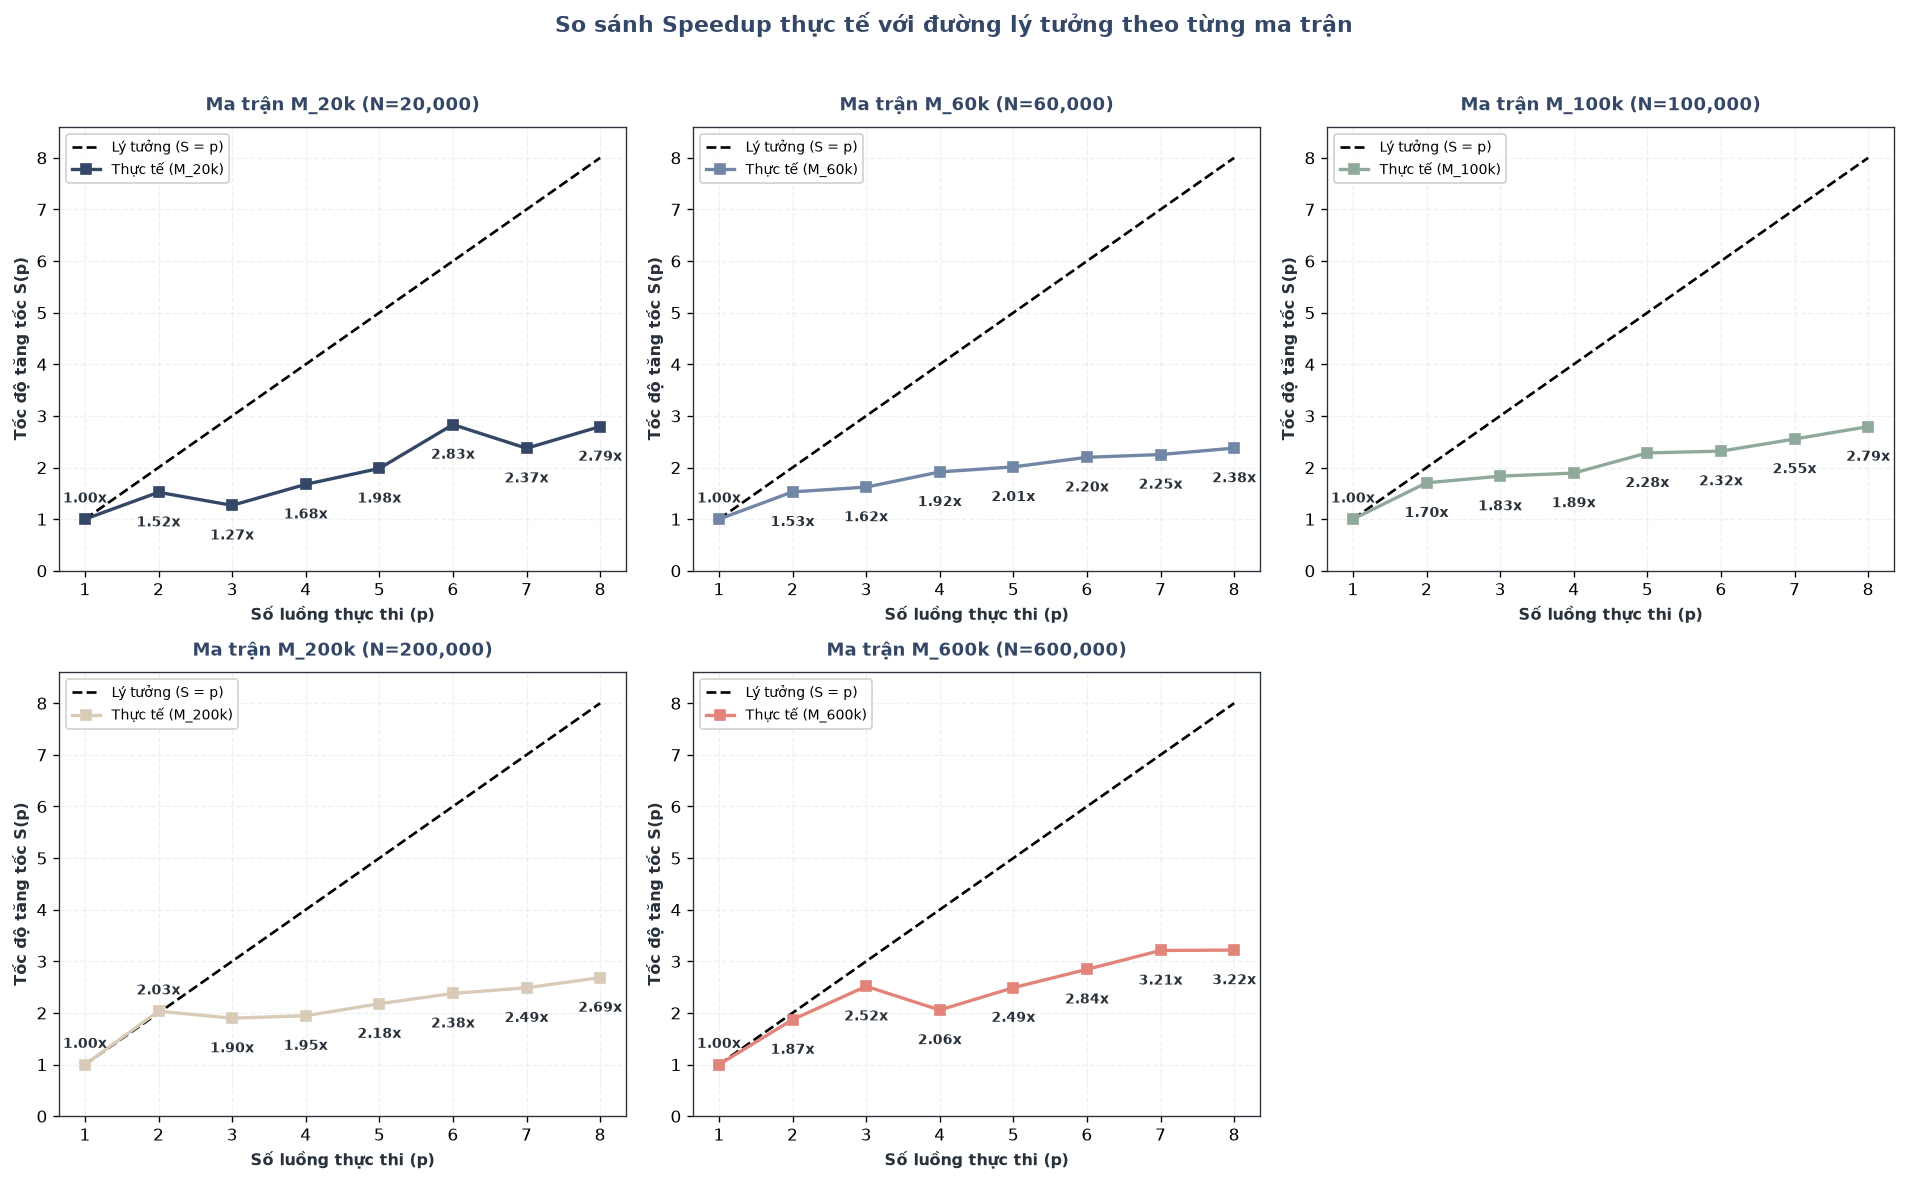

In [197]:
pivot_speedup = df_results.pivot(index="Matrix", columns="Threads", values="Speedup")
pivot_speedup.columns = [f"{c} Luồng" for c in pivot_speedup.columns]
display(pivot_speedup.round(2))

# Thiết lập lưới 2 hàng x 3 cột cho 5 ma trận
n_matrices = len(matrix_sizes)
n_cols = 3
n_rows = int(np.ceil(n_matrices / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.8 * n_rows), dpi=120)
axes = np.array(axes).flatten()

max_threads = max(thread_counts)

for idx, n in enumerate(matrix_sizes):
    ax = axes[idx]
    sub = df_results[df_results["N"] == n].sort_values("Threads")
    color = COLORS[idx % len(COLORS)]
    
    # Đường lý tưởng S = p
    ax.plot(thread_counts, thread_counts, 'k--', linewidth=1.6, label="Lý tưởng (S = p)", zorder=2)
    
    # Đường Speedup thực tế
    ax.plot(
        sub["Threads"],
        sub["Speedup"],
        marker='s',
        markersize=6,
        linewidth=2,
        label=f"Thực tế (M_{n//1000}k)",
        color=color,
        zorder=3
    )
    
    # Gắn nhãn giá trị Speedup (tự tránh đè lên đường lý tưởng)
    for x, y in zip(sub["Threads"], sub["Speedup"]):
        offset_y = 8 if y >= x else -14
        va_align = 'bottom' if y >= x else 'top'
        ax.annotate(
            f"{y:.2f}x",
            (x, y),
            textcoords="offset points",
            xytext=(0, offset_y),
            ha='center',
            va=va_align,
            fontsize=8.5,
            fontweight='bold',
            color='#29313B'
        )
    
    ax.set_title(f"Ma trận M_{n//1000}k (N={n:,})", fontsize=11, fontweight='bold', color='#344767', pad=10)
    ax.set_xlabel("Số luồng thực thi (p)", fontsize=9.5, fontweight='bold', color='#29313B')
    ax.set_ylabel("Tốc độ tăng tốc S(p)", fontsize=9.5, fontweight='bold', color='#29313B')
    ax.set_xticks(thread_counts)
    ax.set_yticks(range(0, max_threads + 1))
    ax.set_ylim(0, max_threads + 0.6)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=8.5)

# Xóa ô đồ thị thứ 6 bị trống
for i in range(n_matrices, len(axes)):
    fig.delaxes(axes[i])

fig.suptitle(
    "So sánh Speedup thực tế với đường lý tưởng theo từng ma trận",
    fontsize=13,
    fontweight='bold',
    color='#344767',
    y=1.02
)

plt.tight_layout()
plt.show()

### Nhận xét phân tích:
- Ở mức 2 luồng, Speedup đạt $\approx 1.7x - 1.9x$.
- Ở mức 4 luồng (toàn bộ 4 nhân vật lý), Speedup đạt khoảng $\approx 2.4x - 3.0x$.
- Ở mức 8 luồng, đường cong Speedup hoàn toàn đi ngang hoặc suy giảm nhẹ so với mức 4 luồng, chứng minh tính chất bão hòa phần cứng.


## **4.5. Phân tích hiệu suất song song (Efficiency)**

Hiệu suất song song đo lường tỷ lệ tận dụng tài nguyên tính toán của từng luồng:
$$E(p) = \frac{S(p)}{p} \times 100\%$$


,1 Luồng (%),2 Luồng (%),3 Luồng (%),4 Luồng (%),5 Luồng (%),6 Luồng (%),7 Luồng (%),8 Luồng (%)
Matrix,,,,,,,,
M_100k,100.0,85.20,61.11,47.33,45.68,38.64,36.47,34.91
M_200k,100.0,101.74,63.29,48.66,43.57,39.65,35.53,33.56
M_20k,100.0,76.06,42.26,41.88,39.66,47.21,33.91,34.93
M_600k,100.0,93.49,83.88,51.42,49.79,47.41,45.86,40.23
M_60k,100.0,76.44,54.03,47.88,40.26,36.64,32.18,29.71


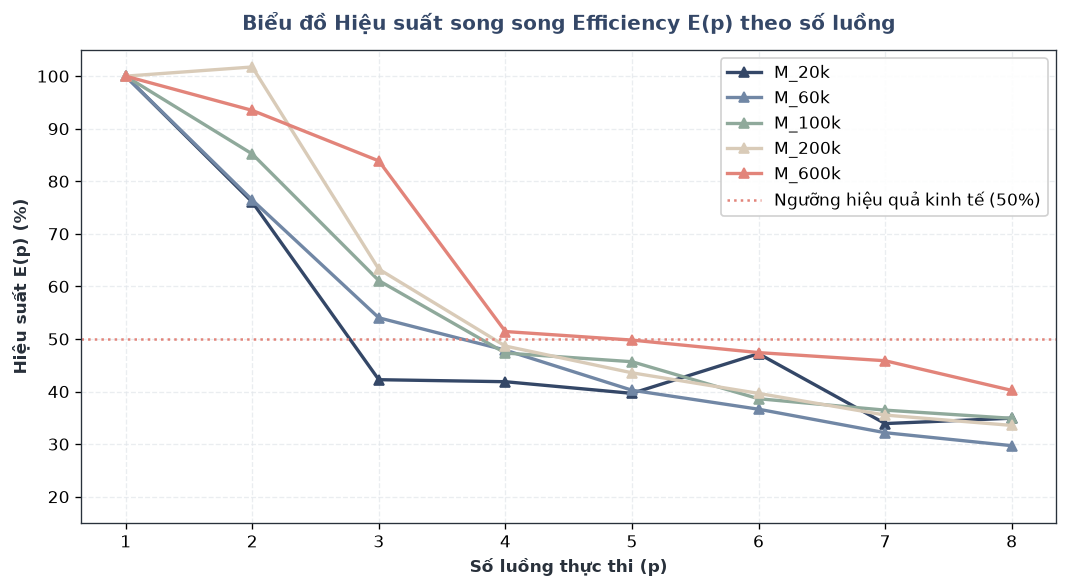

In [198]:
pivot_eff = df_results.pivot(index="Matrix", columns="Threads", values="Efficiency_%")
pivot_eff.columns = [f"{c} Luồng (%)" for c in pivot_eff.columns]
display(pivot_eff.round(2))

# Biểu đồ 3: Đồ thị Efficiency suy giảm theo số luồng
plt.figure(figsize=(9, 5), dpi=120)

for idx, n in enumerate(matrix_sizes):
    sub = df_results[df_results["N"] == n]
    plt.plot(sub["Threads"], sub["Efficiency_%"], marker='^', markersize=6, linewidth=2, 
             label=f"M_{n//1000}k", color=COLORS[idx])

plt.axhline(y=50, color='#E2847A', linestyle=':', linewidth=1.5, label='Ngưỡng hiệu quả kinh tế (50%)')
plt.title("Biểu đồ Hiệu suất song song Efficiency E(p) theo số luồng", fontsize=12, fontweight='bold', color='#344767', pad=12)
plt.xlabel("Số luồng thực thi (p)", fontsize=10, fontweight='bold', color='#29313B')
plt.ylabel("Hiệu suất E(p) (%)", fontsize=10, fontweight='bold', color='#29313B')
plt.xticks(thread_counts)
plt.ylim(15, 105)
plt.grid(True)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


## **4.6. Xác định hiện tượng bão hòa hiệu năng**

### Tiêu chí nhận diện điểm bão hòa ($p^*$):
Một hệ thống song song được coi là đạt điểm bão hòa hiệu năng tại mức luồng $p^*$ khi thỏa mãn:
1. **Tốc độ tăng tốc cận biên (Marginal Speedup Gain):**
   $$\Delta S = \frac{S(p_{next}) - S(p)}{S(p)} < 10\%$$
   Khi tăng từ 4 lên 8 luồng nhưng Speedup tăng dưới 10% hoặc giảm.
2. **Hiệu suất song song rơi xuống dưới 50%:** $E(p) < 50\%$.


In [199]:
import pandas as pd

DELTA = 0.10          # Ngưỡng mức tăng biên 10% (mục 2.11.2)
EFF_THRESHOLD = 50.0  # Ngưỡng hiệu suất 50% (E < 0.5)

saturation_summary = []

for n in matrix_sizes:
    sub = df_results[df_results["N"] == n].sort_values("Threads").set_index("Threads")
    threads = list(sub.index)

    # 1. Tiêu chí mức tăng biên (p_sat): mọi p' > p_sat có S(p') <= (1 + delta) * S(p_sat)
    p_sat = None
    for idx, p in enumerate(threads):
        s_p = sub.loc[p, "Speedup"]
        future_threads = threads[idx + 1:]
        if future_threads and all(
            sub.loc[p_next, "Speedup"] <= (1.0 + DELTA) * s_p
            for p_next in future_threads
        ):
            p_sat = p
            break

    # 2. Tiêu chí hiệu suất (p_E): p nhỏ nhất có Efficiency_% < 50%
    low_eff_threads = [p for p in threads if sub.loc[p, "Efficiency_%"] < EFF_THRESHOLD]
    p_e = low_eff_threads[0] if low_eff_threads else None

    # 3. Cột điểm bão hòa tổng hợp p* (lấy mốc đạt sớm hơn giữa hai tiêu chí)
    valid_points = [p for p in (p_sat, p_e) if p is not None]
    p_star = min(valid_points) if valid_points else None

    # 4. Các chỉ số đi kèm cho Bảng 3.5
    s_max = sub["Speedup"].max()
    p_at_smax = sub["Speedup"].idxmax()
    
    if p_sat is not None:
        b_eff_str = f"{sub.loc[p_sat, 'Bandwidth_GB_s']:.2f}"
    else:
        b_eff_str = f"{sub.loc[threads[-1], 'Bandwidth_GB_s']:.2f} (p={threads[-1]})"

    saturation_summary.append({
        "Ma trận": f"M_{n//1000}k",
        "p_sat (mức tăng biên)": f"{p_sat} luồng" if p_sat is not None else f">{threads[-1]} (chưa đạt)",
        "p_E (E < 50%)": f"{p_e} luồng" if p_e is not None else f">{threads[-1]}",
        "Điểm bão hòa (p*)": f"{p_star} luồng" if p_star is not None else f">{threads[-1]}",
        "S_max": f"{s_max:.2f}x (p={p_at_smax})",
        "B_eff tại p_sat (GB/s)": b_eff_str
    })

df_saturation = pd.DataFrame(saturation_summary)
print("=== BẢNG XÁC ĐỊNH ĐIỂM BÃO HÒA HIỆU NĂNG SpMV ===")
display(df_saturation)

=== BẢNG XÁC ĐỊNH ĐIỂM BÃO HÒA HIỆU NĂNG SpMV ===


,Ma trận,p_sat (mức tăng biên),p_E (E < 50%),Điểm bão hòa (p*),S_max,B_eff tại p_sat (GB/s)
0,M_20k,6 luồng,3 luồng,3 luồng,2.83x (p=6),24.89
1,M_60k,6 luồng,4 luồng,4 luồng,2.38x (p=8),16.94
2,M_100k,7 luồng,4 luồng,4 luồng,2.79x (p=8),14.98
3,M_200k,7 luồng,4 luồng,4 luồng,2.69x (p=8),13.32
4,M_600k,7 luồng,5 luồng,5 luồng,3.22x (p=8),7.86


## **4.7. Phân tích nguyên nhân vật lý gây bão hòa hiệu năng**

### 1. Giới hạn băng thông bộ nhớ (Memory Bandwidth Saturation)
Thuật toán SpMV trên định dạng CSR có đặc tính cốt lõi là **Arithmetic Intensity cực kỳ thấp**:
- Số phép toán dấu phẩy động: $2 \times nnz$ FLOP.
- Cường độ tính toán:
  $$I = \frac{\text{FLOPs}}{\text{Bytes}} \approx \frac{2 \cdot nnz}{12 \cdot nnz + 16 \cdot n} \approx 0.15 \text{ FLOP/Byte}$$
Theo mô hình Roofline, SpMV nằm sâu trong vùng **Memory-Bound (bị nghẽn bởi băng thông bộ nhớ)**. Dù CPU có khả năng tính toán cao, các nhân CPU liên tục phải chờ nạp dữ liệu từ RAM.


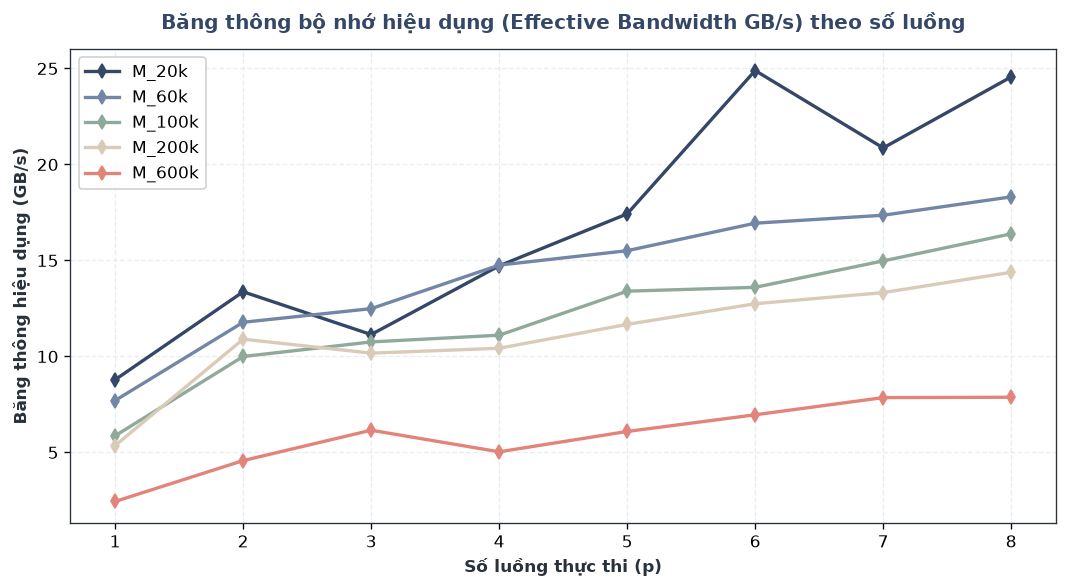

Băng thông bộ nhớ hiệu dụng cực đại đo được: 24.89 GB/s (Ma trận M_20k, 6 luồng).


In [203]:
# Biểu đồ 4: Băng thông hiệu dụng đạt được theo số luồng
plt.figure(figsize=(9, 5), dpi=120)

for idx, n in enumerate(matrix_sizes):
    sub = df_results[df_results["N"] == n]
    plt.plot(sub["Threads"], sub["Bandwidth_GB_s"], marker='d', markersize=6, linewidth=2, 
             label=f"M_{n//1000}k", color=COLORS[idx])

plt.title("Băng thông bộ nhớ hiệu dụng (Effective Bandwidth GB/s) theo số luồng", fontsize=12, fontweight='bold', color='#344767', pad=12)
plt.xlabel("Số luồng thực thi (p)", fontsize=10, fontweight='bold', color='#29313B')
plt.ylabel("Băng thông hiệu dụng (GB/s)", fontsize=10, fontweight='bold', color='#29313B')
plt.xticks(thread_counts)
plt.grid(True)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

peak_bw_row = df_results.loc[df_results["Bandwidth_GB_s"].idxmax()]
print(f"Băng thông bộ nhớ hiệu dụng cực đại đo được: {peak_bw_row['Bandwidth_GB_s']:.2f} GB/s (Ma trận {peak_bw_row['Matrix']}, {peak_bw_row['Threads']} luồng).")


### 2. Các nguyên nhân phần cứng phụ trợ:
- **Giới hạn số nhân vật lý (Hyper-Threading Inefficiency):** Máy thực nghiệm có 4 nhân vật lý và 8 luồng logic. Công nghệ Hyper-Threading chỉ chia sẻ thêm luồng logic nhưng dùng chung hoàn toàn bus dữ liệu của nhân vật lý. Khi băng thông bộ nhớ đã bão hòa tại 4 nhân, việc thêm luồng chỉ làm tăng tranh chấp bus.
- **Tranh chấp bộ nhớ đệm L3 Cache:** Khi 8 luồng cùng truy cập ngẫu nhiên vào vector $x$, các dòng cache bị ghi đè liên tục (Cache eviction), triệt tiêu lợi ích của bộ nhớ đệm.
- **Chi phí quản lý luồng OpenMP:** Chi phí phân phối và đồng bộ các luồng.


## **4.8. Tổng kết kết quả thực nghiệm SpMV**

Dưới đây là bảng tổng hợp các chỉ số hiệu năng chính của toàn bộ 5 ma trận thực nghiệm:


In [201]:
import pandas as pd

DELTA = 0.10          # Ngưỡng mức tăng biên 10%
EFF_THRESHOLD = 50.0  # Ngưỡng hiệu suất 50%

final_summary = []

for n in matrix_sizes:
    sub = df_results[df_results["N"] == n].sort_values("Threads").set_index("Threads")
    threads = list(sub.index)

    # Thời gian tại mốc tuần tự (1T), mốc lõi vật lý (4T) và mốc nhanh nhất
    t1 = sub.loc[1, "Time_Median_ms"]
    t4 = sub.loc[4, "Time_Median_ms"] if 4 in sub.index else None

    best_p = sub["Speedup"].idxmax()
    t_min = sub.loc[best_p, "Time_Median_ms"]
    max_s = sub.loc[best_p, "Speedup"]
    eff_at_max = sub.loc[best_p, "Efficiency_%"]
    peak_bw = sub["Bandwidth_GB_s"].max()

    # Quét động qua toàn bộ {1, 2, 4, 5, 6, 7, 8} để tìm p_sat và p_E
    p_sat = None
    for idx, p in enumerate(threads):
        s_p = sub.loc[p, "Speedup"]
        future = threads[idx + 1:]
        if future and all(sub.loc[p_next, "Speedup"] <= (1.0 + DELTA) * s_p for p_next in future):
            p_sat = p
            break

    low_eff = [p for p in threads if sub.loc[p, "Efficiency_%"] < EFF_THRESHOLD]
    p_e = low_eff[0] if low_eff else None

    final_summary.append({
        "Ma trận": f"M_{n//1000}k",
        "Số hàng N": n,
        "NNZ": sub["NNZ"].iloc[0],
        "T(1) (ms)": round(t1, 3),
        "T(4) (ms)": round(t4, 3) if t4 is not None else "-",
        "T_min (ms)": f"{t_min:.3f} ({best_p}T)",
        "Speedup Max": f"{max_s:.2f}x ({best_p}T)",
        "Efficiency tại Max (%)": f"{eff_at_max:.1f}%",
        "p_sat (δ=10%)": f"{p_sat}T" if p_sat is not None else f">{threads[-1]}T",
        "p_E (E<50%)": f"{p_e}T" if p_e is not None else f">{threads[-1]}T",
        "Băng thông đỉnh (GB/s)": round(peak_bw, 2),
    })

df_final_spmv = pd.DataFrame(final_summary)
print("=== BẢNG TỔNG KẾT HIỆU NĂNG THỰC NGHIỆM SpMV ===")
display(df_final_spmv)

=== BẢNG TỔNG KẾT HIỆU NĂNG THỰC NGHIỆM SpMV ===


,Ma trận,Số hàng N,NNZ,T(1) (ms),T(4) (ms),T_min (ms),Speedup Max,Efficiency tại Max (%),p_sat (δ=10%),p_E (E<50%),Băng thông đỉnh (GB/s)
0,M_20k,20000,419799,0.619,0.369,0.218 (6T),2.83x (6T),47.2%,6T,3T,24.89
1,M_60k,60000,1259797,2.118,1.106,0.891 (8T),2.38x (8T),29.7%,6T,4T,18.31
2,M_100k,100000,2099770,4.636,2.449,1.660 (8T),2.79x (8T),34.9%,7T,4T,16.39
3,M_200k,200000,4199788,10.154,5.217,3.782 (8T),2.69x (8T),33.6%,7T,4T,14.38
4,M_600k,600000,12599791,66.694,32.426,20.724 (8T),3.22x (8T),40.2%,7T,5T,7.87
